# Week 6: Visualizing cis-eQTL Associations with LD

## This week at a glance

**Big idea:** In Week 3 my LocusZoom plot showed a "tower" of significant SNPs near ERAP2, and I explained it with LD: SNPs near the strongest one are inherited with it, so they share its signal. This week I actually measure that. For one gene, I calculate the LD (r²) between the lead SNP and every other SNP, and color the LocusZoom plot by it. I also scale the eQTL scan to every gene on chromosome 22.

**What I cover**
- What LD r² between two SNPs means, and how to calculate it
- How LocusZoom plots color SNPs by LD with the lead variant
- Counting significant cis-eQTLs across a whole chromosome

**My readings**
| Paper / resource | What I read | Why it matters |
|---|---|---|
| LocusZoom (locuszoom.org), Pruim et al. 2010, *Bioinformatics* | The LocusZoom tutorial | The standard tool for plotting association results around one locus in papers |
| CAVIAR (optional) | Overview | A fine-mapping method that uses LD to find the likely causal SNP (coming in later weeks) |

**My tasks**
1. Follow the LocusZoom tutorial.
2. Plot cis-eQTL associations for one gene locus:
   - y-axis: -log10(p) of each cis-eQTL
   - x-axis: genomic position
   - color: LD r² between the lead variant and each other variant

**Weekly questions I answer on Gradescope**
1. How many significant cis-eQTLs did I find on chromosome 22? (threshold: p < 0.05 / number of SNP-gene pairs tested)
2. For one gene locus, how many cis-eQTLs have LD r² > 0.8 with the lead variant?
3. Same, for r² > 0.5?
4. Same, for r² > 0.1?
5. Include a LocusZoom plot for my favorite gene locus.

**My data**
- Genotypes: 1000 Genomes European samples, chromosome 22 (`../data/raw/LDREF/`)
- Gene expression: Geuvadis LCL RNA-seq (`../data/raw/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt`)

## Biology background and vocabulary

### Lead variant

The **lead variant** (lead SNP) is the SNP with the smallest p-value for a gene, the tallest dot on the LocusZoom plot. In Week 3, ERAP2's lead SNP was rs2762.

### LD r²: how much two SNPs travel together

From Week 1: SNPs close together are rarely split up when DNA is passed down, so they tend to be inherited together. **LD r²** measures how strongly two SNPs move together across people, from 0 to 1.

It's calculated the same way as R² in Week 4, except both sides are genotypes. Line up everyone's copies at SNP A and SNP B, and square the correlation.

**Toy example (6 people):**

| Person | Copies at lead SNP | Copies at SNP B | Copies at SNP C |
|---|---|---|---|
| 1 | 0 | 0 | 1 |
| 2 | 0 | 0 | 0 |
| 3 | 1 | 1 | 2 |
| 4 | 1 | 1 | 0 |
| 5 | 2 | 2 | 1 |
| 6 | 2 | 2 | 0 |

- **SNP B** matches the lead SNP for every person, so r² = 1. Its LocusZoom dot would be as tall as the lead's, because it carries the exact same signal.
- **SNP C** has no pattern with the lead SNP, so r² is near 0. If it's still tall on the plot, it's a **separate** signal, not a copy of the lead.

| r² | Meaning |
|---|---|
| close to 1 | Nearly always inherited together. Can't tell them apart statistically |
| around 0.5 | Partly linked |
| close to 0 | Independent |

### Why color by LD?

Coloring each dot by its r² with the lead SNP answers one question at a glance: **is this tall dot just a copy of the lead, or its own signal?**

| Color (standard LocusZoom) | r² with lead SNP |
|---|---|
| Purple diamond | The lead SNP itself |
| Red | 0.8 to 1.0 |
| Orange | 0.6 to 0.8 |
| Green | 0.4 to 0.6 |
| Light blue | 0.2 to 0.4 |
| Dark blue | 0 to 0.2 |

In a typical locus, the red and orange dots are clustered tall around the lead, and the blue dots are lower. A tall **blue** dot is interesting: a possible second, independent eQTL.

### Why this matters for fine-mapping

All the red SNPs have almost the same p-value as the lead, so the data alone can't say which one is causal. Fine-mapping methods (like CAVIAR) use exactly this LD information to give each SNP a probability of being the causal one. That's the next few weeks.

### Week 6 terms

| Term | Meaning |
|---|---|
| **Lead variant** | The SNP with the smallest p-value for a gene |
| **LD r²** | Squared correlation of two SNPs' genotypes across people (0 to 1) |
| **Gene locus** | A gene plus the region of DNA around it (here, ±500 kb) |
| **SNP-gene pair** | One test: one SNP against one gene's expression |
| **LocusZoom** | A plot of -log10(p) vs. position, colored by LD with the lead SNP |
| **Independent signal** | A significant SNP with low LD to the lead, so it's not just a copy |
| **CAVIAR** | A fine-mapping method that uses LD to estimate which SNP is causal |

## Task 1: cis-eQTLs for every gene on chromosome 22

### Step 1: Load the data for chromosome 22

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bed_reader import open_bed
from scipy import stats

genotype_folder = "../data/raw/LDREF"
expression_path = "../data/raw/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt"
chromosome = 22
cis_window_size = 500_000

expression_table = pd.read_csv(expression_path, sep="\t").set_index("TargetID")

fam_column_names = ["family_id", "person_id", "dad_id", "mom_id", "sex", "trait_value"]
people_table = pd.read_csv(f"{genotype_folder}/1000G.EUR.{chromosome}.fam", sep=r"\s+", header=None, names=fam_column_names)
is_in_both = people_table["person_id"].isin(set(expression_table.columns[3:])).to_numpy()
shared_people = people_table.loc[is_in_both, "person_id"].tolist()

bim_column_names = ["chromosome", "snp_id", "genetic_distance", "position", "counted_allele", "other_allele"]
snp_table = pd.read_csv(f"{genotype_folder}/1000G.EUR.{chromosome}.bim", sep=r"\s+", header=None, names=bim_column_names)
snp_positions = snp_table["position"].to_numpy()

with open_bed(f"{genotype_folder}/1000G.EUR.{chromosome}.bed") as bed_file:
    genotypes = bed_file.read(index=np.s_[np.flatnonzero(is_in_both), :], dtype="float64")
genotypes = np.where(np.isnan(genotypes), np.nanmean(genotypes, axis=0), genotypes)

genes_on_chromosome = expression_table[expression_table["Chr"].astype(str) == str(chromosome)]

print("People in both datasets:", len(shared_people))
print("SNPs on chromosome 22:", len(snp_table))
print("Genes on chromosome 22:", len(genes_on_chromosome))

People in both datasets: 344
SNPs on chromosome 22: 17489
Genes on chromosome 22: 633


**What I see:** I see the same 344 people as before, 17,489 SNPs on chromosome 22 (the same count as Week 2), and 633 genes on chromosome 22 in the expression file.

### Step 2: Test every SNP-gene pair

Same regression as Weeks 3 and 4: for each gene, test every SNP within ±500 kb. I reuse the matrix version of the regression from Week 4.

In [2]:
def regress_expression_on_snps(expression_values, snp_genotypes):
    """Simple linear regression of expression on each SNP (each column). Returns slope, p-value, R² per SNP."""
    number_of_people = len(expression_values)
    centered_expression = expression_values - expression_values.mean()
    centered_genotypes = snp_genotypes - snp_genotypes.mean(axis=0)
    genotype_spread = (centered_genotypes ** 2).sum(axis=0)
    expression_spread = (centered_expression ** 2).sum()
    shared_spread = centered_genotypes.T @ centered_expression
    with np.errstate(divide="ignore", invalid="ignore"):
        slope = shared_spread / genotype_spread
        r_squared = shared_spread ** 2 / (genotype_spread * expression_spread)
        standard_error = np.sqrt(expression_spread * (1 - r_squared) / (number_of_people - 2) / genotype_spread)
        p_value = 2 * stats.t.sf(np.abs(slope / standard_error), df=number_of_people - 2)
    no_variation = genotype_spread == 0
    slope[no_variation], r_squared[no_variation], p_value[no_variation] = np.nan, np.nan, np.nan
    return pd.DataFrame({"slope": slope, "p_value": p_value, "r_squared": r_squared})


all_pairs = []
for gene_id, gene_info in genes_on_chromosome.iterrows():
    first = np.searchsorted(snp_positions, int(gene_info["Coord"]) - cis_window_size, side="left")
    last = np.searchsorted(snp_positions, int(gene_info["Coord"]) + cis_window_size, side="right")
    if last == first:
        continue
    gene_expression = expression_table.loc[gene_id, shared_people].to_numpy(dtype=float)
    results = regress_expression_on_snps(gene_expression, genotypes[:, first:last])
    results.insert(0, "gene_id", gene_id)
    results.insert(1, "snp_id", snp_table["snp_id"].to_numpy()[first:last])
    results.insert(2, "position", snp_positions[first:last])
    results["column"] = np.arange(first, last)
    all_pairs.append(results)

all_pairs = pd.concat(all_pairs, ignore_index=True).dropna(subset=["p_value"])
all_pairs["neg_log10_p"] = -np.log10(all_pairs["p_value"])

print("Genes tested:", all_pairs["gene_id"].nunique())
print("SNP-gene pairs tested:", len(all_pairs))

Genes tested: 633
SNP-gene pairs tested: 270853


**What I see:** I tested all 633 genes and 270,853 SNP-gene pairs in total. That's far more tests than one gene's 510, which is why the cutoff in the next step gets much stricter.

### Step 3: Count the significant cis-eQTLs (Gradescope question 1)

Bonferroni over **every** SNP-gene pair on the chromosome: 0.05 / 270,853.

In [3]:
number_of_tests = len(all_pairs)
bonferroni_cutoff = 0.05 / number_of_tests
significant_pairs = all_pairs[all_pairs["p_value"] < bonferroni_cutoff]

print(f"Bonferroni cutoff: 0.05 / {number_of_tests:,} = {bonferroni_cutoff:.2e}")
print("Significant cis-eQTLs (SNP-gene pairs):", len(significant_pairs))
print("Unique SNPs among them:", significant_pairs["snp_id"].nunique())
print("Genes with at least one:", significant_pairs["gene_id"].nunique())

strongest_genes = (significant_pairs.groupby("gene_id")
                   .agg(lead_p_value=("p_value", "min"), significant_snps=("snp_id", "size"))
                   .sort_values("lead_p_value"))
strongest_genes.head(5)

Bonferroni cutoff: 0.05 / 270,853 = 1.85e-07
Significant cis-eQTLs (SNP-gene pairs): 1320
Unique SNPs among them: 960
Genes with at least one: 72


,lead_p_value,significant_snps
gene_id,,
ENSG00000100376.7,3.256798e-87,28
ENSG00000184674.7,2.032860e-74,49
ENSG00000172404.4,3.611015e-68,89
ENSG00000100321.10,6.332549e-59,30
ENSG00000260065.1,4.482008e-57,48


**What I see:** With a cutoff of 1.85e-7, I found **1,320 significant cis-eQTLs** (SNP-gene pairs) on chromosome 22. They involve 960 unique SNPs (some SNPs are eQTLs for more than one gene) and 72 of the 633 genes (11%).

The strongest gene is ENSG00000100376, which is **FAM118A** (lead p = 3.3e-87, 28 significant SNPs). I pick it as my gene locus for the rest of this notebook.

11% is lower than the 24% on chromosome 5 in Week 4, but the cutoff here is much stricter: Week 4 used a separate cutoff per gene (about 0.05 / 400), while this one corrects for all 270,853 tests on the chromosome at once.

## Task 2: LocusZoom plot colored by LD

### Step 4: Find the lead variant for FAM118A

In [4]:
gene_id = strongest_genes.index[0]
gene_label = "FAM118A"
gene_position = int(expression_table.loc[gene_id, "Coord"])

locus = all_pairs[all_pairs["gene_id"] == gene_id].reset_index(drop=True)
lead_snp = locus.loc[locus["p_value"].idxmin()]

print(gene_label, gene_id, "at position", gene_position)
print("SNPs tested in the locus:", len(locus))
print("Lead SNP:", lead_snp["snp_id"], "at", int(lead_snp["position"]), f"(p = {lead_snp['p_value']:.1e}, slope = {lead_snp['slope']:.2f})")

FAM118A ENSG00000100376.7 at position 45704849
SNPs tested in the locus: 618
Lead SNP: rs104664 at 45711854 (p = 3.3e-87, slope = 13.17)


**What I see:** The FAM118A locus has 618 SNPs within ±500 kb. The lead SNP is **rs104664**, with p = 3.3e-87.

### Step 5: Calculate LD r² between the lead SNP and every other SNP

r² = squared correlation of the two SNPs' copies across the 489 1000 Genomes people (the reference panel, same people used for clumping in Week 5).

The same step in PLINK:

```bash
plink --bfile ../data/raw/LDREF/1000G.EUR.22 --r2 --ld-snp rs104664 \
      --ld-window-kb 1000 --ld-window 99999 --ld-window-r2 0 --out fam118a_ld
```

In [5]:
with open_bed(f"{genotype_folder}/1000G.EUR.{chromosome}.bed") as bed_file:
    panel_genotypes = bed_file.read(index=np.s_[:, locus["column"].to_numpy()], dtype="float64")
panel_genotypes = np.where(np.isnan(panel_genotypes), np.nanmean(panel_genotypes, axis=0), panel_genotypes)

lead_copies = panel_genotypes[:, locus["column"].to_numpy() == lead_snp["column"]].ravel()
locus["ld_r2"] = [np.corrcoef(lead_copies, panel_genotypes[:, k])[0, 1] ** 2 for k in range(panel_genotypes.shape[1])]

top_snps = locus[["snp_id", "position", "p_value", "ld_r2"]].sort_values("p_value").head(12).copy()
top_snps["p_value"] = top_snps["p_value"].map("{:.1e}".format)
top_snps.round({"ld_r2": 3})

,snp_id,position,p_value,ld_r2
341,rs104664,45711854,3.3e-87,1.000
362,rs6006992,45742760,3.5e-86,0.974
374,rs1569413,45756081,3.5e-86,0.974
376,rs136564,45764874,3.5e-86,0.974
377,rs470062,45767369,3.5e-86,0.974
354,rs3827393,45736153,3.5e-86,0.965
361,rs3747240,45740224,6.3e-84,0.965
366,rs5765272,45747901,7.7e-84,0.965
392,rs136611,45794283,7.8e-81,0.965
381,rs5765304,45771974,7.8e-81,0.965


**What I see:** The lead, rs104664, has r² = 1 with itself. The next 10 SNPs have r² between 0.90 and 0.97 with it, so they are near-copies, and their p-values are almost as small (between 1e-66 and 1e-86). After those, r² drops sharply: the 12th SNP, rs1003505, has r² of only 0.33 and a much weaker p-value. That's the LD tower measured directly: the SNPs that share the lead's genotypes share its signal.

### Step 6: Count significant cis-eQTLs by LD with the lead (Gradescope questions 2 to 4)

In [6]:
locus["is_significant"] = locus["p_value"] < bonferroni_cutoff
significant_in_locus = locus[locus["is_significant"]]
other_significant = significant_in_locus[significant_in_locus["snp_id"] != lead_snp["snp_id"]]

print("Significant cis-eQTLs in the locus:", len(significant_in_locus))
for ld_cutoff in [0.8, 0.5, 0.1]:
    with_lead = (significant_in_locus["ld_r2"] > ld_cutoff).sum()
    without_lead = (other_significant["ld_r2"] > ld_cutoff).sum()
    print(f"r² > {ld_cutoff}: {with_lead} including the lead SNP ({without_lead} besides it)")

Significant cis-eQTLs in the locus: 28
r² > 0.8: 11 including the lead SNP (10 besides it)
r² > 0.5: 11 including the lead SNP (10 besides it)
r² > 0.1: 20 including the lead SNP (19 besides it)


**What I see:** FAM118A has 28 significant cis-eQTLs:

| LD with lead (rs104664) | Including the lead | Besides the lead |
|---|---|---|
| r² > 0.8 | 11 | 10 |
| r² > 0.5 | 11 | 10 |
| r² > 0.1 | 20 | 19 |

So 11 SNPs are near-copies of the lead, and the counts don't change between 0.8 and 0.5: there's a sharp break between SNPs that are tightly linked to the lead and the rest. Another 9 are partly linked (r² between 0.1 and 0.5), and 8 significant SNPs have r² of 0.1 or below, which means they're largely independent of the lead. Those could be a **second eQTL signal** for FAM118A, which would be worth checking with fine-mapping. I can't say that for sure from this plot alone, since a weak link to the lead can still explain part of a signal.

### Step 7: The LocusZoom plot (Gradescope question 5)

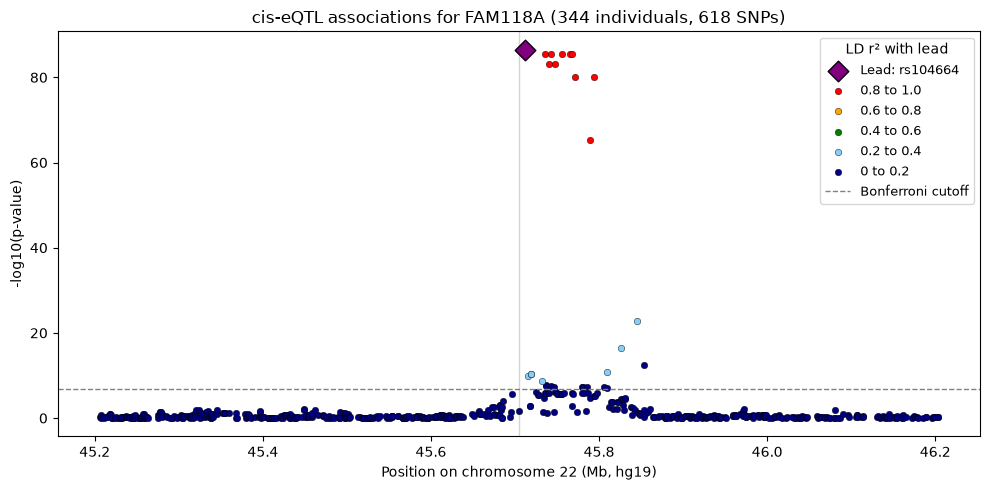

In [7]:
ld_bins = [(0.8, 1.01, "red", "0.8 to 1.0"), (0.6, 0.8, "orange", "0.6 to 0.8"), (0.4, 0.6, "green", "0.4 to 0.6"),
           (0.2, 0.4, "lightskyblue", "0.2 to 0.4"), (0.0, 0.2, "navy", "0 to 0.2")]

figure, axis = plt.subplots(figsize=(10, 5))
others = locus[locus["snp_id"] != lead_snp["snp_id"]]
for low, high, color, label in ld_bins[::-1]:
    in_bin = others[(others["ld_r2"] >= low) & (others["ld_r2"] < high)]
    axis.scatter(in_bin["position"] / 1e6, in_bin["neg_log10_p"], s=22, color=color, edgecolor="black", linewidth=0.3, label=label)
axis.scatter(lead_snp["position"] / 1e6, lead_snp["neg_log10_p"], s=110, marker="D", color="purple", edgecolor="black",
             label=f"Lead: {lead_snp['snp_id']}", zorder=3)
axis.axhline(-np.log10(bonferroni_cutoff), color="gray", linestyle="--", linewidth=1, label="Bonferroni cutoff")
axis.axvline(gene_position / 1e6, color="lightgray", linewidth=1, zorder=0)

handles, labels = axis.get_legend_handles_labels()
order = [labels.index(f"Lead: {lead_snp['snp_id']}")] + [labels.index(b[3]) for b in ld_bins] + [labels.index("Bonferroni cutoff")]
axis.legend([handles[i] for i in order], [labels[i] for i in order], title="LD r² with lead", loc="upper right", fontsize=9)
axis.set_xlabel(f"Position on chromosome {chromosome} (Mb, hg19)")
axis.set_ylabel("-log10(p-value)")
axis.set_title(f"cis-eQTL associations for {gene_label} (344 individuals, {len(locus)} SNPs)")
plt.tight_layout()
plt.savefig("week6_fam118a_locuszoom.png", dpi=200)
plt.show()

**What I see:** The purple diamond (rs104664) sits at the top with a cluster of red SNPs right next to it at almost the same height, between -log10(p) of about 65 and 87: those are the 10 near-copies. Then there's a big gap. No SNPs are orange or green (r² 0.4 to 0.8), which matches the sharp break in Step 6. The next tallest SNPs are light blue (r² 0.2 to 0.4), reaching about 23, just to the right of the red cluster. A few dark blue dots also sit above the dashed Bonferroni line: these are the significant SNPs that are nearly independent of the lead. Far from the gene, everything is flat near 0. The plot is saved as `week6_fam118a_locuszoom.png` for Gradescope.

### Optional: the official LocusZoom tool

The tutorial's interactive LocusZoom ([my.locuszoom.org](https://my.locuszoom.org)) takes an uploaded table and computes LD itself. This cell writes FAM118A's results in a format it accepts. I don't upload anything that isn't public: these are summary statistics only, with no individual genotypes.

In [8]:
upload_table = locus.merge(snp_table[["snp_id", "counted_allele", "other_allele"]], on="snp_id")
upload_table = pd.DataFrame({
    "chrom": chromosome, "pos": upload_table["position"], "ref": upload_table["other_allele"],
    "alt": upload_table["counted_allele"], "rsid": upload_table["snp_id"], "pvalue": upload_table["p_value"],
    "beta": upload_table["slope"],
}).sort_values("pos")
upload_table.to_csv("week6_fam118a_for_locuszoom.tsv", sep="\t", index=False)
print("Wrote week6_fam118a_for_locuszoom.tsv with", len(upload_table), "rows")

Wrote week6_fam118a_for_locuszoom.tsv with 618 rows


## Readings guide

---

### LocusZoom (Pruim et al. 2010, *Bioinformatics*; locuszoom.org)

**What it's about:** A tool for plotting association results in one region of the genome. It became the standard figure for showing a GWAS or eQTL signal in papers.

**My notes:**
- Each dot is one SNP: x = position, y = -log10(p).
- Dots are colored by LD r² with a reference SNP (usually the lead), using reference panels like 1000 Genomes.
- The plot also shows where genes are, so a reader can see which genes sit under a signal.
- The color tells me at a glance whether a tall SNP is a copy of the lead (red) or a possible separate signal (blue).
- There are two versions: the original (a command-line R/Python tool) and LocusZoom.js (interactive, in the browser, at my.locuszoom.org).

---

### CAVIAR (optional)

**What it's about:** A fine-mapping method. Given the association results and the LD between SNPs in a locus, it estimates which SNPs are most likely causal.

**My notes:**
- It outputs a "causal set": the smallest group of SNPs that contains the causal one(s) with high probability (for example, 95%).
- It needs exactly what I built this week: per-SNP association statistics and the LD between SNPs.
- This connects to GTEx's fine-mapping result from my literature review (a median of about 6 candidate variants per eQTL).

## Week 6 answers

### Gradescope questions

**1. How many significant cis-eQTLs did you find on chromosome 22?**
I tested 270,853 SNP-gene pairs across 633 genes on chromosome 22 (344 individuals, SNPs within ±500 kb of each gene). Using a Bonferroni cutoff of 0.05 / 270,853 = 1.85e-7, I found 1,320 significant cis-eQTLs (SNP-gene pairs), involving 960 unique SNPs and 72 genes.

**2. For one gene locus, how many cis-eQTLs have LD r² > 0.8 with the lead variant?**
For FAM118A (lead variant rs104664, p = 3.3e-87), 11 of its 28 significant cis-eQTLs have r² > 0.8 with the lead, including the lead itself (10 besides it).

**3. Same, r² > 0.5?**
11 (10 besides the lead). No significant SNPs fall between 0.5 and 0.8.

**4. Same, r² > 0.1?**
20 (19 besides the lead). The remaining 8 significant SNPs have r² of 0.1 or below, suggesting a possible second, independent eQTL signal.

**5. LocusZoom plot**
`week6_fam118a_locuszoom.png` (saved by Step 7).